## iraqdata — إنهاء معاناة جمع البيانات الاقتصادية في العراق
### مقدمة إلى مكتبة البيانات
التحليل الكمي للاقتصاد العراقي باستخدام بايثون

**المكتبة المستخدمة:** 

iraqdata (v1.0.0):

[https://github.com/HusseinKh90/iraqdata](https://github.com/HusseinKh90/iraqdata)

[https://pypi.org/project/iraqdata/](https://pypi.org/project/iraqdata/)


---
### الهدف من هذا الملف:
التعرف على كيفية استدعاء المؤشرات الاقتصادية الكلية للعراق (المعروض النقدي ، الرقم القياسي لأسعار المستهلك) مباشرة وبسطر برمجي واحد، دون الحاجة للتعامل مع ملفات بي دي اف مبعثرة أو جداول إكسل يدوية.

In [1]:
# لتثبيت مكتبة البيانات لأول مرة
!pip install iraqdata

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# تثبيت واستيراد الحزم الأساسية

import iraqdata as id
import pandas as pd
import matplotlib.pyplot as plt

print(f"تم استيراد iraqdata بنجاح — الإصدار: {id.__version__}")

تم استيراد iraqdata بنجاح — الإصدار: 1.0.0


In [3]:
# ضمان الموثوقية الأكاديمية (Reproducibility) عبر تثبيت الإصدار الرسمي
# هذا الإجراء يضمن أن يحصل أي باحث حول العالم على نفس الأرقام المتطابقة
id.set_release("data-2026-10")
print("مصدر البيانات المعتمد:", id.get_data_source())

مصدر البيانات المعتمد: release data-2026-10 (pinned with set_release) from husseinkh90/iraqdata


In [4]:
#  عرض سلسلتي الرقم القياسي لاسعار المستهلك والمعروض النقدي الواسع
# مع تخصيص أسماء الأعمدة وتحديد الفترة من عام 2020
df = id.get_series({"Broad_Money_M2": "m2", "Headline_CPI": "cpi"}, start="2020-01")
df.tail(15)

C:\Users\msi-pc\AppData\Local\Temp\ipykernel_39268\3606382944.py:3: FlagWarning: Result contains break (B) or provisional (P) values: Broad_Money_M2 1 P; Headline_CPI 1 B, 12 P. Pass flags=True to see them.
  df = id.get_series({"Broad_Money_M2": "m2", "Headline_CPI": "cpi"}, start="2020-01")


,Broad_Money_M2,Headline_CPI
date,,
2025-06,170744.0,106.7
2025-07,172815.0,106.6
2025-08,170657.0,107.4
2025-09,170264.0,107.6
2025-10,170188.0,107.3
2025-11,170031.0,106.8
2025-12,167282.0,106.8
2026-01,169812.0,107.8
2026-02,172185.0,108.9


In [5]:
# لاختبار أثر التوسع النقدي على الأسعار
# يتم حساب التضخم السنوي ومعدلات النمو السنوي للمعروض النقدي الواسع
df_yoy = df.pct_change(12) * 100
df_yoy.columns = ["M2_Growth_YoY", "CPI_Inflation_YoY"]
df_combined = df.join(df_yoy).dropna()
df_combined[["M2_Growth_YoY", "CPI_Inflation_YoY"]].tail(6)

,M2_Growth_YoY,CPI_Inflation_YoY
date,,
2026-03,1.394160,2.218115
2026-04,4.756379,4.263207
2026-05,6.515391,2.962963
2026-06,2.816497,3.092784
2026-07,-0.816480,3.283302
2026-08,1.335427,3.258845


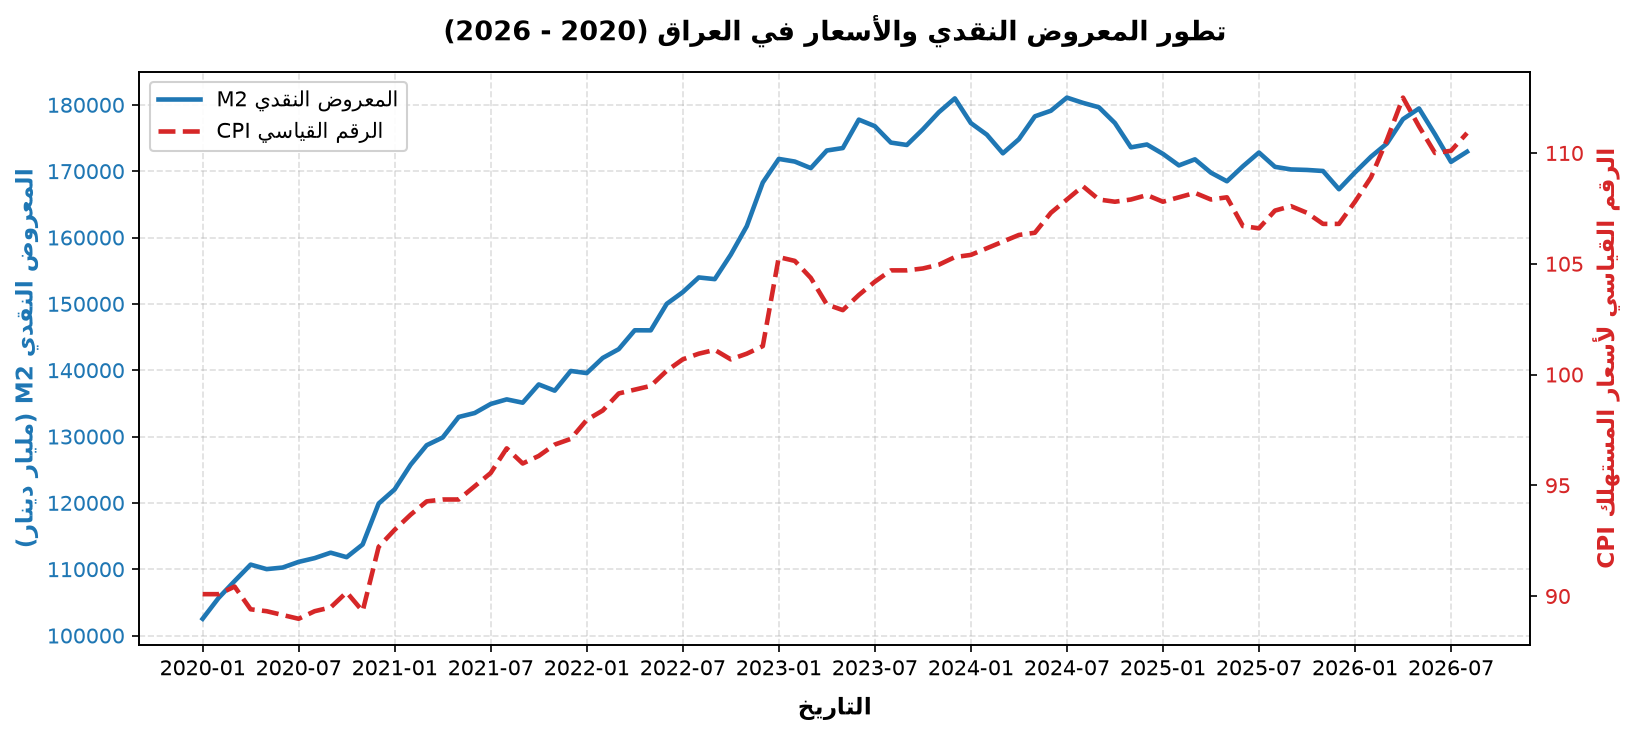

In [6]:
# الرسم البياني للتضخم السنوي ومعدلات النمو السنوي لعرض النقد
fig, ax1 = plt.subplots(figsize=(11, 5), dpi=150)

color_m2 = "#1f77b4"
ax1.set_xlabel("التاريخ", fontsize=11, fontweight="bold", labelpad=8)
ax1.set_ylabel("المعروض النقدي M2 (مليار دينار)", color=color_m2, fontsize=11, fontweight="bold")
line1 = ax1.plot(df.index, df["Broad_Money_M2"], color=color_m2, lw=2.2, label="المعروض النقدي M2")
ax1.tick_params(axis="y", labelcolor=color_m2)

# إظهار التاريخ كل 6 أشهر وبشكل أفقي لمنع التداخل نهائياً
ticks_step = 6
ax1.set_xticks(range(0, len(df.index), ticks_step))
ax1.set_xticklabels(df.index[::ticks_step], rotation=0, fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.4)

# محور اليمين للتضخم
ax2 = ax1.twinx()
color_cpi = "#d62728"
ax2.set_ylabel("الرقم القياسي لأسعار المستهلك CPI", color=color_cpi, fontsize=11, fontweight="bold")
line2 = ax2.plot(df.index, df["Headline_CPI"], color=color_cpi, lw=2.2, linestyle="--", label="الرقم القياسي CPI")
ax2.tick_params(axis="y", labelcolor=color_cpi)

# دمج مفتاح الرسم (Legend) في صندوق موحد وواضح
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True, facecolor="white", framealpha=0.9)

plt.title("تطور المعروض النقدي والأسعار في العراق (2020 - 2026)", fontsize=13, fontweight="bold", pad=15)
fig.tight_layout()
plt.show()

## الخلاصة والنتيجة:
 1. تم استخدام مكتبة بايثون المتاحة لبيانات الاقتصاد العراقي، تم استدعاء بيانات نقدية وسعرية موثقة ورسمية من البنك المركزي العراقي ووزارة التخطيط عبر سطر برمجي واحد ومباشرة
 2. نلاحظ مسار التوسع في السيولة النقدية بالتوازي مع حركة الأسعار وتعديلات سعر الصرف

iraqdata (v1.0.0):

https://github.com/HusseinKh90/iraqdata

https://pypi.org/project/iraqdata/